# Border Regions Visualization

This notebook visualizes the Southern Border regions (DE-AT-IT Alps crossing) used in the border sensitivity analysis.

**Border NUTS2 Regions:**
- **Austria:** AT33, AT34
- **Italy:** ITC4, ITH1, ITH2, ITH3
- **Germany:** DE14, DE21, DE27

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import numpy as np

# Configure matplotlib
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
})

BASE_PATH = Path.cwd()
print(f"Base path: {BASE_PATH}")

Base path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM


In [2]:
# Define regions
CORRIDOR_COUNTRIES = ['AT', 'DE', 'IT', 'DK', 'SE', 'NO']

SOUTHERN_BORDER_REGIONS = {
    'AT33', 'AT34',                   # Austria - Tyrol, Vorarlberg
    'ITC4', 'ITH1', 'ITH2', 'ITH3',   # Italy - Lombardy, Trentino, Friuli, Veneto
    'DE14', 'DE21', 'DE27'            # Germany - Tübingen, Oberbayern, Schwaben
}

# Region names for labeling
REGION_NAMES = {
    'AT33': 'Tyrol',
    'AT34': 'Vorarlberg',
    'ITC4': 'Lombardy',
    'ITH1': 'Trentino-Alto Adige',
    'ITH2': 'Friuli-Venezia Giulia',
    'ITH3': 'Veneto',
    'DE14': 'Tübingen',
    'DE21': 'Upper Bavaria',
    'DE27': 'Swabia',
}

print(f"Border regions: {len(SOUTHERN_BORDER_REGIONS)} NUTS2 regions")

Border regions: 9 NUTS2 regions


In [3]:
# Load NUTS shapefile
nuts_shp_path = BASE_PATH / 'data' / 'NUTS_RG_20M_2021_4326.shp' / 'NUTS_RG_20M_2021_4326.shp'

if not nuts_shp_path.exists():
    print(f"ERROR: NUTS shapefile not found at {nuts_shp_path}")
else:
    nuts_gdf = gpd.read_file(nuts_shp_path)
    print(f"Loaded {len(nuts_gdf)} NUTS regions")
    print(f"Columns: {nuts_gdf.columns.tolist()}")
    print(f"\nLEVL_CODE values: {nuts_gdf['LEVL_CODE'].unique()}")

Loaded 2010 NUTS regions
Columns: ['NUTS_ID', 'LEVL_CODE', 'CNTR_CODE', 'NAME_LATN', 'NUTS_NAME', 'MOUNT_TYPE', 'URBN_TYPE', 'COAST_TYPE', 'geometry']

LEVL_CODE values: [0 1 2 3]


c:\Users\simuser\miniconda3\envs\antoniasenv\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


In [4]:
# Filter for NUTS2 level and corridor countries
nuts2 = nuts_gdf[nuts_gdf['LEVL_CODE'] == 2].copy()
print(f"NUTS2 regions: {len(nuts2)}")

# Filter for corridor countries
corridor_nuts2 = nuts2[nuts2['CNTR_CODE'].isin(CORRIDOR_COUNTRIES)].copy()
print(f"Corridor NUTS2 regions: {len(corridor_nuts2)}")

# Mark border regions
corridor_nuts2['is_border'] = corridor_nuts2['NUTS_ID'].isin(SOUTHERN_BORDER_REGIONS)
print(f"Border regions found: {corridor_nuts2['is_border'].sum()}")

NUTS2 regions: 334
Corridor NUTS2 regions: 88
Border regions found: 9


In [5]:
# Get country boundaries for context (NUTS0)
nuts0 = nuts_gdf[nuts_gdf['LEVL_CODE'] == 0].copy()
corridor_countries_gdf = nuts0[nuts0['CNTR_CODE'].isin(CORRIDOR_COUNTRIES)]

## Map 1: Full Corridor with Border Regions Highlighted

Saved: figures/border_regions_map_full_corridor.pdf


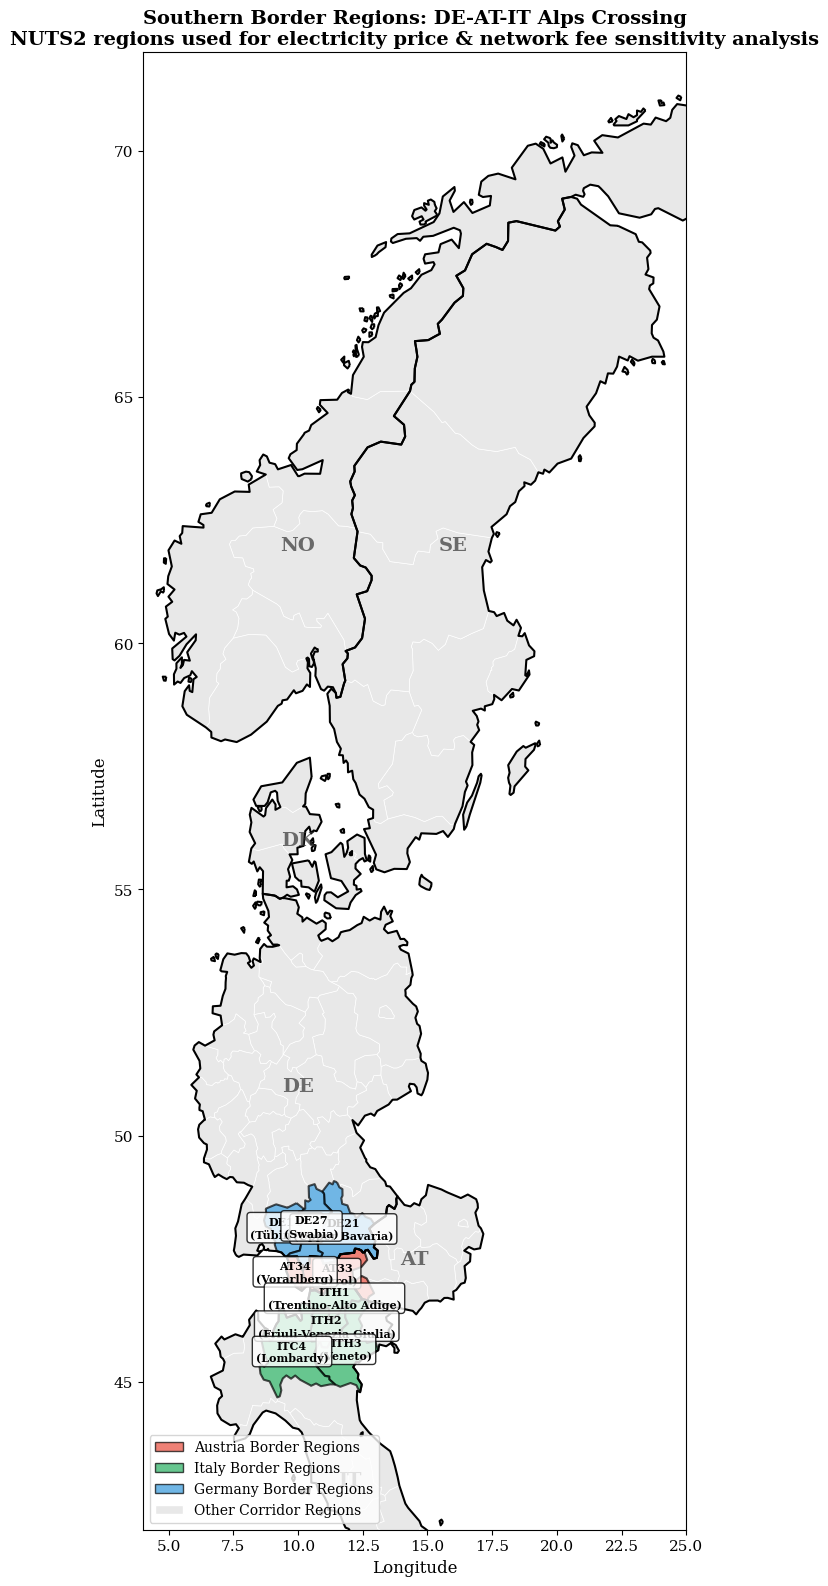

In [6]:
fig, ax = plt.subplots(figsize=(12, 16))

# Plot non-border regions in light gray
non_border = corridor_nuts2[~corridor_nuts2['is_border']]
non_border.plot(ax=ax, color='#E8E8E8', edgecolor='white', linewidth=0.5)

# Plot border regions with country-specific colors
border_regions = corridor_nuts2[corridor_nuts2['is_border']]

colors_by_country = {
    'AT': '#E74C3C',  # Red for Austria
    'IT': '#27AE60',  # Green for Italy
    'DE': '#3498DB',  # Blue for Germany
}

for country, color in colors_by_country.items():
    country_border = border_regions[border_regions['CNTR_CODE'] == country]
    if len(country_border) > 0:
        country_border.plot(ax=ax, color=color, edgecolor='black', linewidth=1.5, alpha=0.7)

# Add country borders
corridor_countries_gdf.boundary.plot(ax=ax, color='black', linewidth=1.5, linestyle='-')

# Add labels for border regions
for idx, row in border_regions.iterrows():
    centroid = row.geometry.centroid
    region_name = REGION_NAMES.get(row['NUTS_ID'], row['NUTS_ID'])
    ax.annotate(f"{row['NUTS_ID']}\n({region_name})", 
                xy=(centroid.x, centroid.y),
                ha='center', va='center',
                fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

# Add country labels
country_labels = {'AT': (14.5, 47.5), 'DE': (10, 51), 'IT': (12, 43),
                  'DK': (10, 56), 'SE': (16, 62), 'NO': (10, 62)}
for country, (x, y) in country_labels.items():
    ax.text(x, y, country, fontsize=14, fontweight='bold', ha='center', va='center',
            color='#333', alpha=0.7)

# Legend
legend_elements = [
    mpatches.Patch(facecolor='#E74C3C', edgecolor='black', label='Austria Border Regions', alpha=0.7),
    mpatches.Patch(facecolor='#27AE60', edgecolor='black', label='Italy Border Regions', alpha=0.7),
    mpatches.Patch(facecolor='#3498DB', edgecolor='black', label='Germany Border Regions', alpha=0.7),
    mpatches.Patch(facecolor='#E8E8E8', edgecolor='white', label='Other Corridor Regions'),
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10)

ax.set_title('Southern Border Regions: DE-AT-IT Alps Crossing\n'
             'NUTS2 regions used for electricity price & network fee sensitivity analysis',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.set_xlim(4, 25)
ax.set_ylim(42, 72)

plt.tight_layout()
plt.savefig(BASE_PATH / 'figures' / 'border_regions_map_full_corridor.pdf', bbox_inches='tight', dpi=150)
plt.savefig(BASE_PATH / 'figures' / 'border_regions_map_full_corridor.png', bbox_inches='tight', dpi=150)
print("Saved: figures/border_regions_map_full_corridor.pdf")
plt.show()

## Map 2: Zoomed View of Border Region (Alps Crossing)

Saved: figures/border_regions_map_zoomed.pdf


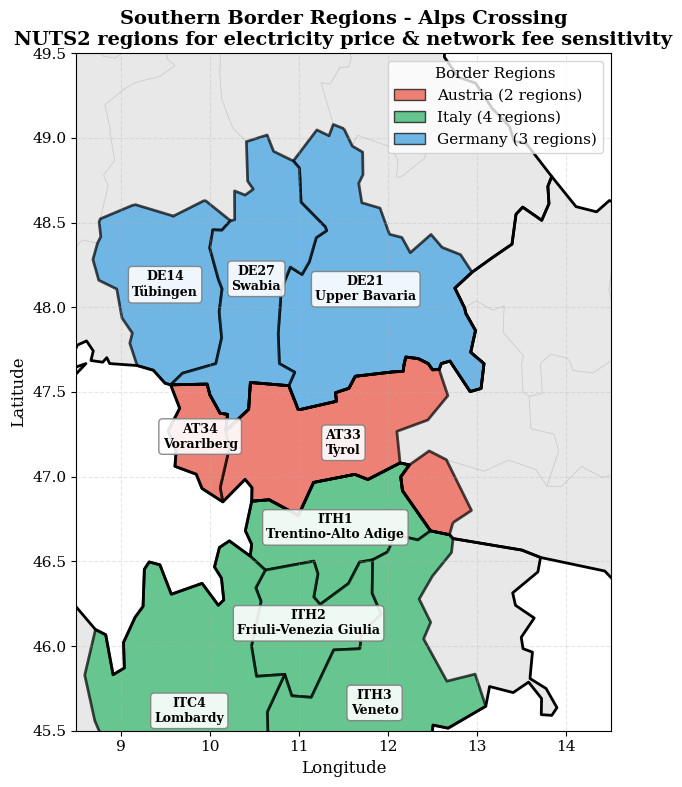

In [7]:
fig, ax = plt.subplots(figsize=(12, 8))

# Plot non-border regions in light gray
non_border.plot(ax=ax, color='#E8E8E8', edgecolor='#CCCCCC', linewidth=0.5)

# Plot border regions with country-specific colors
for country, color in colors_by_country.items():
    country_border = border_regions[border_regions['CNTR_CODE'] == country]
    if len(country_border) > 0:
        country_border.plot(ax=ax, color=color, edgecolor='black', linewidth=2, alpha=0.7)

# Add country borders
corridor_countries_gdf.boundary.plot(ax=ax, color='black', linewidth=2, linestyle='-')

# Add labels for border regions (larger font for zoomed view)
for idx, row in border_regions.iterrows():
    centroid = row.geometry.centroid
    region_name = REGION_NAMES.get(row['NUTS_ID'], row['NUTS_ID'])
    ax.annotate(f"{row['NUTS_ID']}\n{region_name}", 
                xy=(centroid.x, centroid.y),
                ha='center', va='center',
                fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                         edgecolor='gray', alpha=0.9))

# Legend
legend_elements = [
    mpatches.Patch(facecolor='#E74C3C', edgecolor='black', label='Austria (2 regions)', alpha=0.7),
    mpatches.Patch(facecolor='#27AE60', edgecolor='black', label='Italy (4 regions)', alpha=0.7),
    mpatches.Patch(facecolor='#3498DB', edgecolor='black', label='Germany (3 regions)', alpha=0.7),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=11, title='Border Regions')

ax.set_title('Southern Border Regions - Alps Crossing\n'
             'NUTS2 regions for electricity price & network fee sensitivity',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)

# Closer zoom to border region area (Alps crossing)
ax.set_xlim(8.5, 14.5)
ax.set_ylim(45.5, 49.5)

ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig(BASE_PATH / 'figures' / 'border_regions_map_zoomed.pdf', bbox_inches='tight', dpi=150)
plt.savefig(BASE_PATH / 'figures' / 'border_regions_map_zoomed.png', bbox_inches='tight', dpi=150)
print("Saved: figures/border_regions_map_zoomed.pdf")
plt.show()

## Summary Table of Border Regions

In [8]:
# Create summary table
import pandas as pd

summary_data = []
for nuts_id in sorted(SOUTHERN_BORDER_REGIONS):
    region_row = border_regions[border_regions['NUTS_ID'] == nuts_id]
    if len(region_row) > 0:
        row = region_row.iloc[0]
        summary_data.append({
            'NUTS_ID': nuts_id,
            'Country': row['CNTR_CODE'],
            'Region Name': REGION_NAMES.get(nuts_id, row.get('NUTS_NAME', 'Unknown')),
        })

summary_df = pd.DataFrame(summary_data)
print("\n" + "="*60)
print("SOUTHERN BORDER REGIONS SUMMARY")
print("="*60)
print(summary_df.to_string(index=False))
print("\n" + "="*60)
print(f"Total: {len(summary_df)} NUTS2 border regions")
print(f"  Austria: {len(summary_df[summary_df['Country']=='AT'])} regions")
print(f"  Germany: {len(summary_df[summary_df['Country']=='DE'])} regions")
print(f"  Italy: {len(summary_df[summary_df['Country']=='IT'])} regions")


SOUTHERN BORDER REGIONS SUMMARY
NUTS_ID Country           Region Name
   AT33      AT                 Tyrol
   AT34      AT            Vorarlberg
   DE14      DE              Tübingen
   DE21      DE         Upper Bavaria
   DE27      DE                Swabia
   ITC4      IT              Lombardy
   ITH1      IT   Trentino-Alto Adige
   ITH2      IT Friuli-Venezia Giulia
   ITH3      IT                Veneto

Total: 9 NUTS2 border regions
  Austria: 2 regions
  Germany: 3 regions
  Italy: 4 regions
